# Exploratory Data Analysis

### Import Libraries

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Seaborn theme

In [26]:
sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="deep"
)

### Load training data

In [27]:
train_df = pd.read_csv('../data/train.csv')

### First Look

In [28]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,699635.0,349817.000000,201967.372130,0.0,174908.5,349817.0,524725.5,699634.0
Age,699635.0,39.001928,13.800943,7.0,27.0,40.0,50.0,85.0
Flight Distance,699635.0,1353.778702,954.422566,67.0,631.0,954.0,1814.0,4983.0
Inflight wifi service,699635.0,2.778722,1.280419,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,699635.0,3.156210,1.475390,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,699635.0,2.813240,1.329550,0.0,2.0,3.0,4.0,5.0
Gate location,699635.0,3.013734,1.254014,0.0,2.0,3.0,4.0,5.0
Food and drink,699635.0,3.265644,1.300202,0.0,2.0,3.0,4.0,5.0
Online boarding,699635.0,3.364156,1.288538,0.0,2.0,4.0,4.0,5.0
Seat comfort,699635.0,3.568950,1.275333,0.0,3.0,4.0,5.0,5.0


Categorical columns:
- `Inflight wifi service`, 
- `Departure/Arrival time convenient`, 
- `Ease of Online booking`, 
- `Gate location`, 
- `Food and drink`, 
- `Online boarding`, 
- `Seat comfort`, 
- `Inflight entertainment`, 
- `On-board service`, 
- `Leg room service`, 
- `Baggage handling`, 
- `Checkin service`, 
- `Cleanliness`

These categories are scored from 1-5, 0 means unrated (I got this information from the dataset the competition was inspired by)

#### Sus:
- Wait, something don't look right in Departure Delay and Arrival Delay in minutes with only a max being present and no 25%, 50%, 75%
- Are 7 year olds allowed to book a flight? The right question: How does age vary when it comes to satisfaction?
- What is the flight distance measured in? A flight for 67 km?! Are they Taylor Swift? What unit is used?

### Investigate delay distributions

In [29]:
train_df["Departure Delay in Minutes"].describe(
    percentiles=[0.90, 0.95, 0.99]
)

count    699635.000000
mean          1.176209
std           5.982187
min           0.000000
90%           0.000000
95%           7.000000
99%          30.000000
max         489.000000
Name: Departure Delay in Minutes, dtype: float64

In [30]:
(train_df['Departure Delay in Minutes']==0).mean()*100

np.float64(90.78333702573485)

Proves that over 90% of the flights have 0 delay.

##### Statistics

In [31]:
delay = train_df["Departure Delay in Minutes"]

print("Zero delays:", (delay == 0).sum())
print("Non-zero delays:", (delay > 0).sum())
print("Percentage with a delay:", (delay > 0).mean() * 100)
print("Skewness:", delay.skew())

# Percentage of flights with delays greater than 15, 30, and 60 minutes
for threshold in [15, 30, 60]:
    count = (delay > threshold).sum()
    percentage = (delay > threshold).mean() * 100

    print(f"Delays > {threshold} minutes: {count:,} flights ({percentage:.3f}%)")

Zero delays: 635152
Non-zero delays: 64483
Percentage with a delay: 9.216662974265152
Skewness: 12.872163069699234
Delays > 15 minutes: 18,627 flights (2.662%)
Delays > 30 minutes: 6,660 flights (0.952%)
Delays > 60 minutes: 353 flights (0.050%)


Inferences
- <10% of flights that have a delay greater than 0
- Extremely right skewed. Skewness >> 0

### Visualizing Delay Skewness

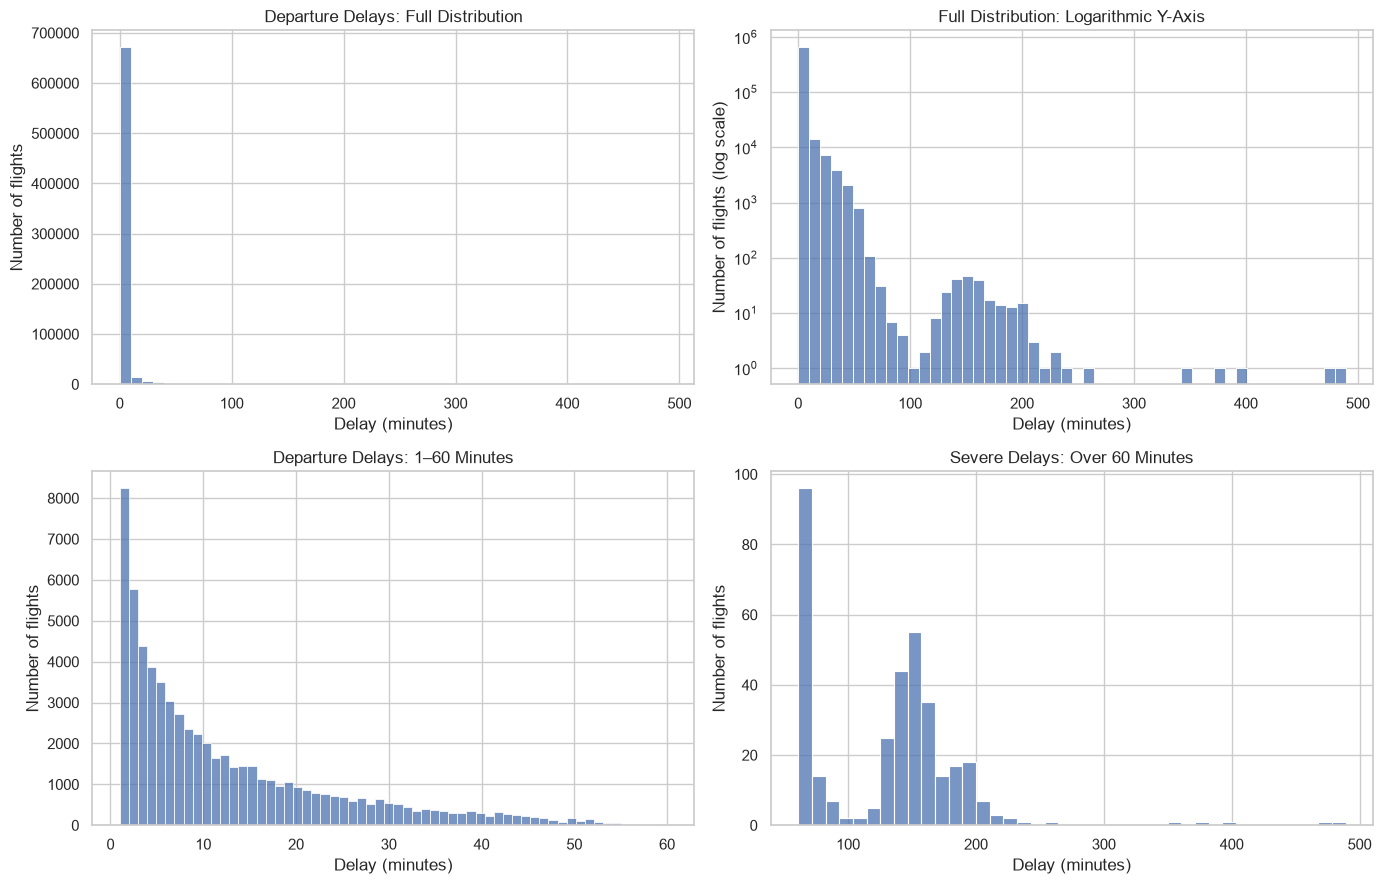

In [32]:
delay = train_df["Departure Delay in Minutes"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Four plots
sns.histplot(data=delay, bins=50, ax=axes[0, 0])
axes[0, 0].set_title("Departure Delays: Full Distribution")
axes[0, 0].set_xlabel("Delay (minutes)")
axes[0, 0].set_ylabel("Number of flights")

# Plot 2: Full distribution with logarithmic y-axis
sns.histplot(data=delay, bins=50, ax=axes[0, 1])
axes[0, 1].set_yscale("log")
axes[0, 1].set_title("Full Distribution: Logarithmic Y-Axis")
axes[0, 1].set_xlabel("Delay (minutes)")
axes[0, 1].set_ylabel("Number of flights (log scale)")

# Plot 3: Focus on delays from 1 to 60 minutes
sns.histplot(data=delay[(delay > 0) & (delay <= 60)], bins=60, ax=axes[1, 0])
axes[1, 0].set_title("Departure Delays: 1–60 Minutes")
axes[1, 0].set_xlabel("Delay (minutes)")
axes[1, 0].set_ylabel("Number of flights")

# Plot 4: Delays greater than 60 minutes
sns.histplot(data=delay[delay > 60], bins=40, ax=axes[1, 1])
axes[1, 1].set_title("Severe Delays: Over 60 Minutes")
axes[1, 1].set_xlabel("Delay (minutes)")
axes[1, 1].set_ylabel("Number of flights")

# Prevent titles and labels from overlapping
plt.tight_layout()
plt.show()

- The graph that speaks to me the most is the logarithmic y axis graph as well as the delay over 60 minutes. Since overall the data is skewed to the right.


### Age distribution

In [33]:
train_df['Age'].describe(percentiles=[0.10, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

count    699635.000000
mean         39.001928
std          13.800943
min           7.000000
10%          22.000000
25%          27.000000
50%          40.000000
75%          50.000000
90%          57.000000
95%          60.000000
99%          68.000000
max          85.000000
Name: Age, dtype: float64

#### Visualization

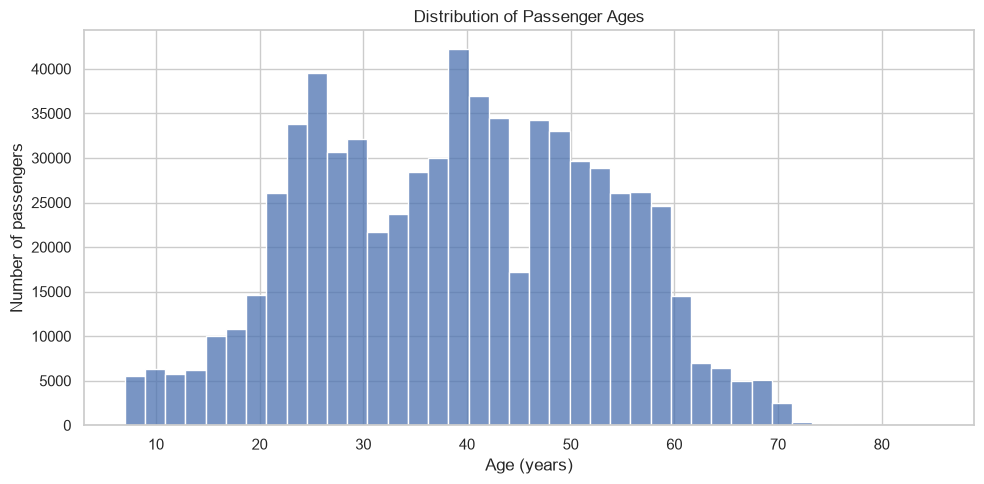

In [34]:
plt.figure(figsize=(10, 5))

sns.histplot(data=train_df, x="Age", bins=40)

plt.title("Distribution of Passenger Ages")
plt.xlabel("Age (years)")
plt.ylabel("Number of passengers")

plt.tight_layout()
plt.show()

- By observing the distribution, I want to make an assumption whether passengers below a certain age are not working and thus only travel for personal trips

#### Understanding distribution of type of travel among ages

In [35]:
train_df["Type of Travel"].value_counts()

Type of Travel
Business travel    497441
Personal Travel    202194
Name: count, dtype: int64

In [36]:
age_bins = [0, 19, 29, 39, 49, 59, 69, 100]
age_labels = [
    "0–19", "20–29", "30–39", "40–49",
    "50–59", "60–69", "70+"
]

train_df["Age Group"] = pd.cut(
    train_df["Age"],
    bins=age_bins,
    labels=age_labels,
    right=True
)

pd.crosstab(
    train_df["Age Group"],
    train_df["Type of Travel"],
    normalize="index"
).mul(100).round(1)

Type of Travel,Business travel,Personal Travel
Age Group,,
0–19,21.8,78.2
20–29,77.1,22.9
30–39,74.1,25.9
40–49,81.6,18.4
50–59,76.6,23.4
60–69,35.2,64.8
70+,27.1,72.9


- Are the 21.8% of business travel in ages 0-19 anomalous or just we assume teens are the new entrepreneurs?
- Hunch was right about personal travel being high in age groups 0-19 and 70+
- Business travel is more prevalent among passengers aged 20–59, while personal travel is more prevalent among passengers under 20 and those aged 60 or older.
- Steep decrease and increase of personal travel from bin 0-19 to 20-29 and from 50-59 to 60-69

### Flight Distance

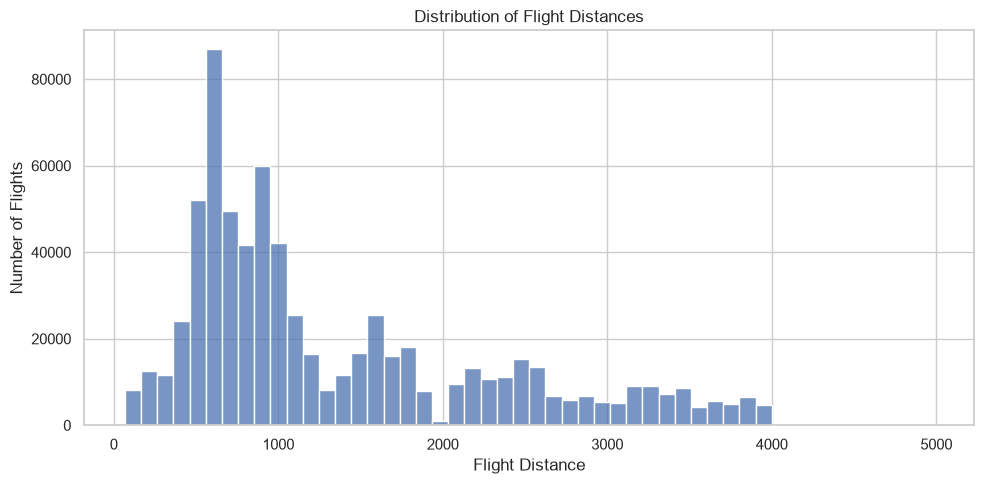

In [37]:
plt.figure(figsize=(10, 5))

sns.histplot(data=train_df, x="Flight Distance", bins=50)

plt.title("Distribution of Flight Distances")
plt.xlabel("Flight Distance")
plt.ylabel("Number of Flights")

plt.tight_layout()
plt.show()

### Actual testing of hypotheses

#### h1: Delays play a huge role

##### Satisfaction when delay vs no delay

In [38]:
delay_satisfaction = pd.crosstab(
    train_df["Departure Delay in Minutes"] > 0,
    train_df["satisfaction"],
    normalize="index"
).mul(100).round(2)

delay_satisfaction

satisfaction,False,True
Departure Delay in Minutes,,
False,55.20,44.80
True,59.96,40.04


##### Satisfaction across levels of delay

In [39]:
delay_bins = [-1, 0, 15, 30, 60, float("inf")]
delay_labels = [
    "No delay",
    "1–15 min",
    "16–30 min",
    "31–60 min",
    "Over 60 min"
]

train_df["Departure Delay Group"] = pd.cut(
    train_df["Departure Delay in Minutes"],
    bins=delay_bins,
    labels=delay_labels
)

pd.crosstab(
    train_df["Departure Delay Group"],
    train_df["satisfaction"],
    normalize="index"
).mul(100).round(2)

satisfaction,False,True
Departure Delay Group,,
No delay,55.20,44.80
1–15 min,57.18,42.82
16–30 min,65.82,34.18
31–60 min,68.57,31.43
Over 60 min,68.56,31.44


- Having any delay increases no satisfaction, but what appears to be strange is 55% false on No delay.

#### Arrival Delay in Minutes

In [40]:
arrival_delay = train_df.loc[
    train_df["Arrival Delay in Minutes"].notna(),
    "Arrival Delay in Minutes"
]

print("Known arrival delays:", len(arrival_delay))
print("Missing arrival delays:", train_df["Arrival Delay in Minutes"].isna().sum())

Known arrival delays: 699343
Missing arrival delays: 292


In [41]:
arrival_bins = [-1, 0, 15, 30, 60, float("inf")]
arrival_labels = [
    "No delay",
    "1–15 min",
    "16–30 min",
    "31–60 min",
    "Over 60 min"
]

train_df["Arrival Delay Group"] = pd.cut(
    train_df["Arrival Delay in Minutes"],
    bins=arrival_bins,
    labels=arrival_labels
)

pd.crosstab(
    train_df["Arrival Delay Group"],
    train_df["satisfaction"],
    normalize="index"
).mul(100).round(2)

satisfaction,False,True
Arrival Delay Group,,
No delay,54.79,45.21
1–15 min,62.78,37.22
16–30 min,69.57,30.43
31–60 min,69.01,30.99
Over 60 min,69.03,30.97


#### Departure delays vs Arrival Delays (Impact on Satisfaction)

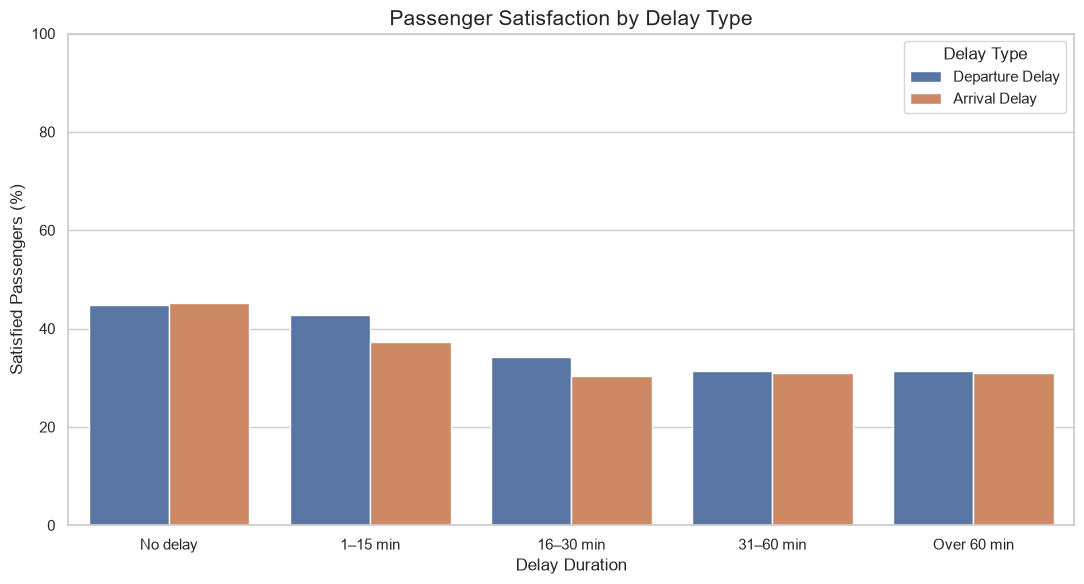

In [42]:
departure_rates = pd.crosstab(
    train_df["Departure Delay Group"],
    train_df["satisfaction"],
    normalize="index"
)[True] * 100

# Satisfaction percentages for arrival delay groups
arrival_rates = pd.crosstab(
    train_df["Arrival Delay Group"],
    train_df["satisfaction"],
    normalize="index"
)[True] * 100
# Combine the satisfaction rates into a DataFrame
comparison = pd.concat(
    [
        departure_rates.rename("Departure Delay"),
        arrival_rates.rename("Arrival Delay")
    ],
    axis=1
).reset_index(names="Delay Group")

# Convert to long format for Seaborn
comparison_long = comparison.melt(
    id_vars="Delay Group",
    var_name="Delay Type",
    value_name="Satisfaction (%)"
)

# Plot
plt.figure(figsize=(11, 6))

sns.barplot(
    data=comparison_long,
    x="Delay Group",
    y="Satisfaction (%)",
    hue="Delay Type"
)

plt.title("Passenger Satisfaction by Delay Type", fontsize=15)
plt.xlabel("Delay Duration")
plt.ylabel("Satisfied Passengers (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="Delay Type")
plt.tight_layout()
plt.show()


- Satisfaction is lesser with respect to arrival delay

#### h2: Service ratings matter

##### Starting with Wi-fi

In [43]:
wifi_satisfaction = pd.crosstab(
    train_df["Inflight wifi service"],
    train_df["satisfaction"],
    normalize="index"
).mul(100).round(2)

wifi_satisfaction

satisfaction,False,True
Inflight wifi service,,
0,11.27,88.73
1,60.93,39.07
2,72.96,27.04
3,72.38,27.62
4,37.78,62.22
5,4.96,95.04


- No rating given shows high satisfaction, and obviously rating >4 shows high satisfaction.
- The unusual trend from 1-3 drop then a slight increase, why is poor wifi service having higher satisfaction than mid-okay?


##### Rest of the cols

In [44]:
rating_cols = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness"
]

In [45]:
rating_summary = {}

for col in rating_cols:
    rates = pd.crosstab(
        train_df[col],
        train_df["satisfaction"],
        normalize="index"
    ).mul(100)

    rating_summary[col] = rates[True]

In [46]:
rating_summary

{'Inflight wifi service': Inflight wifi service
 0    88.734544
 1    39.066633
 2    27.042864
 3    27.623132
 4    62.221390
 5    95.036042
 Name: True, dtype: float64,
 'Departure/Arrival time convenient': Departure/Arrival time convenient
 0    47.765135
 1    50.604805
 2    45.315014
 3    44.885728
 4    40.159753
 5    43.734587
 Name: True, dtype: float64,
 'Ease of Online booking': Ease of Online booking
 0    70.758415
 1    41.458885
 2    31.371091
 3    32.036265
 4    55.642526
 5    75.431927
 Name: True, dtype: float64,
 'Gate location': Gate location
 0    54.295533
 1    51.439141
 2    46.474290
 3    33.724546
 4    41.051588
 5    62.481622
 Name: True, dtype: float64,
 'Food and drink': Food and drink
 0    21.893491
 1    17.067806
 2    39.351749
 3    40.656198
 4    52.535517
 5    56.549776
 Name: True, dtype: float64,
 'Online boarding': Online boarding
 0    62.042200
 1    10.528235
 2     8.535839
 3    12.837238
 4    64.191515
 5    87.510957
 Name: 

- Food and drink, seat comfort, inflight entertainment, on-board service, leg room, baggage handling, check-in service, cleanliness *generally increasing*
- Inflight Wi-Fi, online booking, gate location, online boarding are *non-monotonic*
- Departure/Arrival Time convenient is insconsistent
- Baggage handling has no 0 rating, meaning it is mandatory or made to look mandatory

##### Count

In [47]:
train_df["Inflight wifi service"].value_counts().sort_index()

Inflight wifi service
0     13102
1    107739
2    186870
3    184436
4    128136
5     79352
Name: count, dtype: int64

#### heatmap

In [50]:
rating_heatmap = pd.DataFrame()

for col in rating_cols:
    rates = pd.crosstab(
        train_df[col],
        train_df["satisfaction"],
        normalize="index"
    ).mul(100)

    rating_heatmap[col] = rates[True].drop(index=0, errors="ignore")

rating_heatmap.index.name = "Rating"
rating_heatmap.columns.name = "Service Feature"

rating_heatmap = rating_heatmap.T
rating_heatmap

Rating,1,2,3,4,5
Service Feature,,,,,
Inflight wifi service,39.066633,27.042864,27.623132,62.221390,95.036042
Departure/Arrival time convenient,50.604805,45.315014,44.885728,40.159753,43.734587
Ease of Online booking,41.458885,31.371091,32.036265,55.642526,75.431927
Gate location,51.439141,46.474290,33.724546,41.051588,62.481622
Food and drink,17.067806,39.351749,40.656198,52.535517,56.549776
Online boarding,10.528235,8.535839,12.837238,64.191515,87.510957
Seat comfort,17.362585,17.201068,18.486961,57.060064,67.110572
Inflight entertainment,12.666296,17.302653,23.868691,61.954421,67.108992
On-board service,17.449807,22.044728,29.098480,54.128144,65.660312


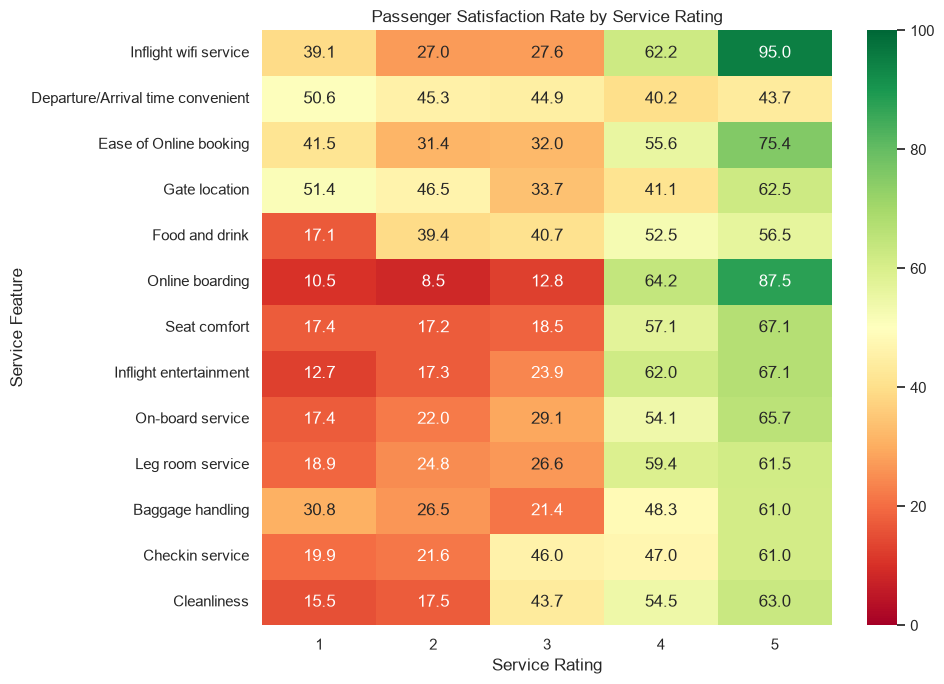

In [51]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    rating_heatmap,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn",
    vmin=0,
    vmax=100
)

plt.title("Passenger Satisfaction Rate by Service Rating")
plt.xlabel("Service Rating")
plt.ylabel("Service Feature")
plt.tight_layout()
plt.show()

- Several service ratings have strong associations with satisfaction, with notable nonlinearities and exceptions.

#### h3: customer loyalty?